
Hidden Layers: [8]
Activation: relu


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Accuracy: 0.9
Test Loss: 0.1983

Hidden Layers: [8]
Activation: tanh
Test Accuracy: 0.9333
Test Loss: 0.2337

Hidden Layers: [8]
Activation: sigmoid
Test Accuracy: 0.9333
Test Loss: 0.4248

Hidden Layers: [16, 8]
Activation: relu
Test Accuracy: 0.9667
Test Loss: 0.0621

Hidden Layers: [16, 8]
Activation: tanh
Test Accuracy: 0.9667
Test Loss: 0.0824

Hidden Layers: [16, 8]
Activation: sigmoid
Test Accuracy: 0.9667
Test Loss: 0.4312

Hidden Layers: [32, 16, 8]
Activation: relu
Test Accuracy: 1.0
Test Loss: 0.0589

Hidden Layers: [32, 16, 8]
Activation: tanh
Test Accuracy: 1.0
Test Loss: 0.0389

Hidden Layers: [32, 16, 8]
Activation: sigmoid
Test Accuracy: 0.9333
Test Loss: 0.3044

Configuration Comparison
Layers		Activation	Accuracy	Loss
[8] 	 relu 		 0.9 		 0.1983
[8] 	 tanh 		 0.9333 		 0.2337
[8] 	 sigmoid 		 0.9333 		 0.4248
[16, 8] 	 relu 		 0.9667 		 0.0621
[16, 8] 	 tanh 		 0.9667 		 0.0824
[16, 8] 	 sigmoid 		 0.9667 		 0.4312
[32, 16, 8] 	 relu 		 1.0 		 0.0589
[32, 16, 8] 

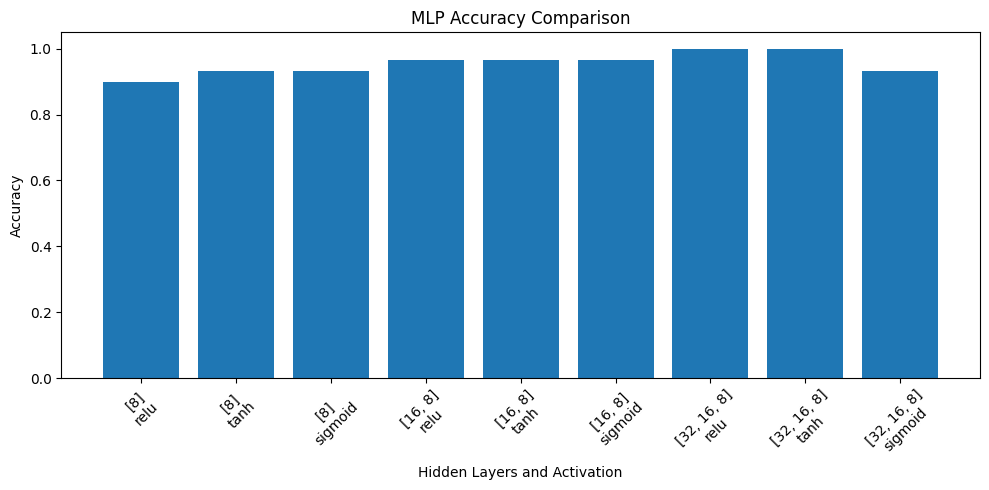

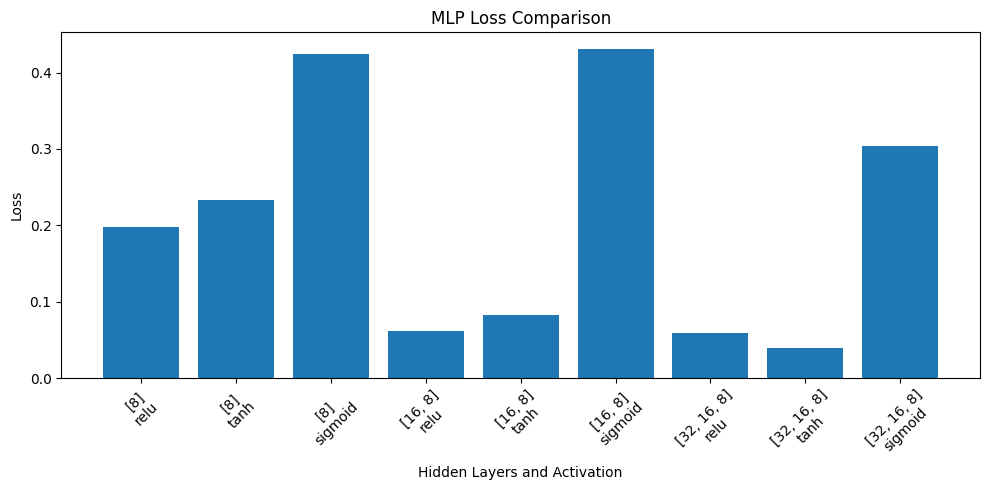

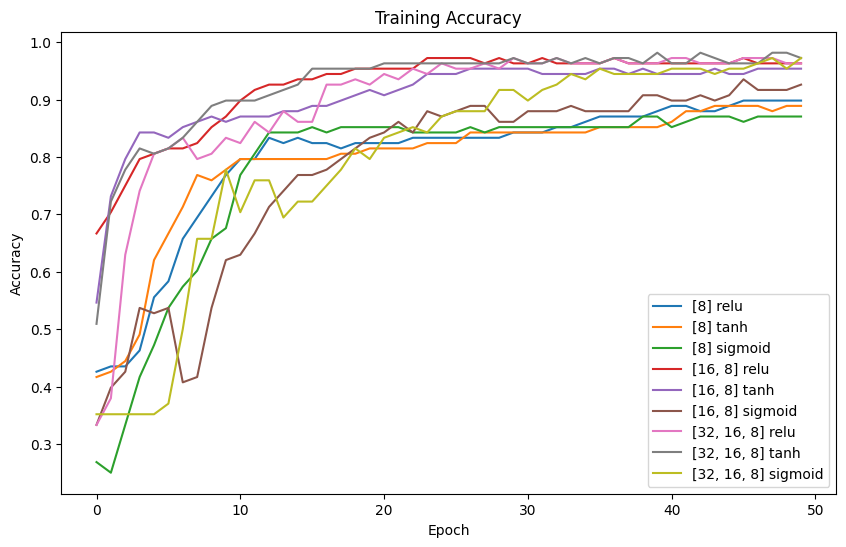

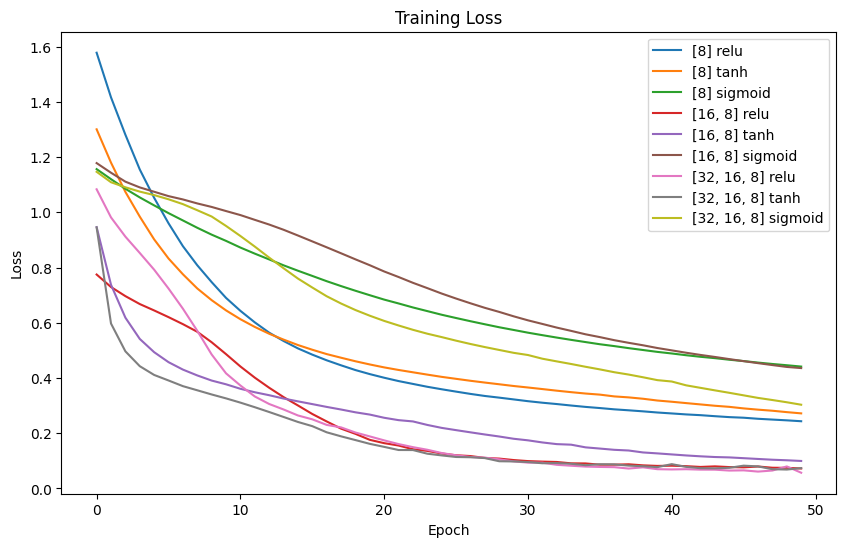


Best Model:
Hidden Layers: [32, 16, 8]
Activation: relu
Accuracy: 1.0
Loss: 0.0589

Enter Iris flower measurements:


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)
classes = iris.target_names

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y)

# Standardize data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create MLP
def create_mlp(layers, activation):
    model = Sequential()
    model.add(Dense(layers[0], input_dim=4, activation=activation))

    for units in layers[1:]:
        model.add(Dense(units, activation=activation))

    model.add(Dense(3, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Different configurations
configs = [[8], [16, 8], [32, 16, 8]]
activations = ['relu', 'tanh', 'sigmoid']

results = []
histories = []

# Train and evaluate models
for layers in configs:
    for activation in activations:

        print("\nHidden Layers:", layers)
        print("Activation:", activation)

        model = create_mlp(layers, activation)

        history = model.fit(
            X_train, y_train,
            epochs=50,
            batch_size=5,
            validation_split=0.1,
            verbose=0
        )

        loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

        print("Test Accuracy:", round(accuracy, 4))
        print("Test Loss:", round(loss, 4))

        results.append([str(layers), activation, accuracy, loss])
        histories.append((str(layers), activation, history))

# Comparison results
print("\nConfiguration Comparison")
print("Layers\t\tActivation\tAccuracy\tLoss")

for r in results:
    print(r[0], "\t", r[1], "\t\t",
          round(r[2], 4), "\t\t", round(r[3], 4))

# Accuracy comparison graph
labels = [r[0] + "\n" + r[1] for r in results]
accuracy = [r[2] for r in results]

plt.figure(figsize=(10, 5))
plt.bar(labels, accuracy)
plt.xlabel("Hidden Layers and Activation")
plt.ylabel("Accuracy")
plt.title("MLP Accuracy Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Loss comparison graph
losses = [r[3] for r in results]

plt.figure(figsize=(10, 5))
plt.bar(labels, losses)
plt.xlabel("Hidden Layers and Activation")
plt.ylabel("Loss")
plt.title("MLP Loss Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot training accuracy of all models
plt.figure(figsize=(10, 6))

for layers, activation, history in histories:
    plt.plot(
        history.history['accuracy'],
        label=layers + " " + activation
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy")
plt.legend()
plt.show()

# Plot training loss of all models
plt.figure(figsize=(10, 6))

for layers, activation, history in histories:
    plt.plot(
        history.history['loss'],
        label=layers + " " + activation
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.show()

# Select the best model
best_index = np.argmax(accuracy)
best_layers = results[best_index][0]
best_activation = results[best_index][1]

print("\nBest Model:")
print("Hidden Layers:", best_layers)
print("Activation:", best_activation)
print("Accuracy:", round(results[best_index][2], 4))
print("Loss:", round(results[best_index][3], 4))

# Train best model again
best_model = create_mlp(
    eval(best_layers),
    best_activation
)

best_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=5,
    verbose=0
)

# Predict new Iris flower
print("\nEnter Iris flower measurements:")

sepal_length = float(input("Sepal length: "))
sepal_width = float(input("Sepal width: "))
petal_length = float(input("Petal length: "))
petal_width = float(input("Petal width: "))

new_data = np.array([[
    sepal_length,
    sepal_width,
    petal_length,
    petal_width
]])

new_data = scaler.transform(new_data)

prediction = best_model.predict(new_data, verbose=0)
predicted_class = np.argmax(prediction)

print("\nPredicted Iris Species:",
      classes[predicted_class])